# Real data

Real observations come with units and an information boundary. Start with a local series, reserve its future, then fit only its past.

**Development notebook.** Expand the library cells to edit the implementation. Examples below use local data and CPU. [Build workflow](README.md#develop-the-package-here).

In [1]:
#| default_exp data.real

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'pyproject.toml').is_file() and (p / 'timegym').is_dir())
plt.style.use('default')
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110,
    'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})

## Build `data.real`

### Imports and configuration

In [3]:
#| export data.real
import numpy as np
import pandas as pd

### get_stock

In [4]:
#| export data.real
def get_stock(ticker, columns='Close'):
    import yfinance
    stock = yfinance.Ticker(ticker).history(period='max', auto_adjust=False)
    #stock = stock.drop(columns=['Adj Close'])
    return stock[columns]

## One origin, three transparent baselines

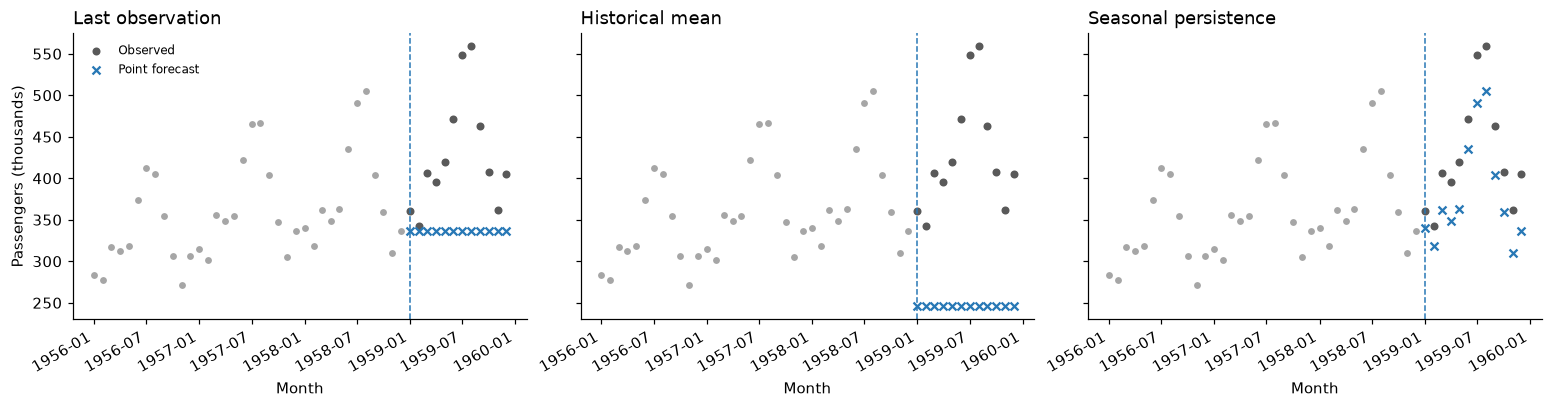

In [5]:
from timegym import Case, ForecastTask, Pipeline, NaiveForecaster
raw = pd.read_csv(ROOT / 'experiments/data/AirPassengers.csv')
series = pd.DataFrame({'passengers': raw['value'].to_numpy(float)},
                      index=pd.period_range('1949-01', periods=len(raw), freq='M'))
context, heldout = series.iloc[:120], series.iloc[120:132]
models = {'Last observation': NaiveForecaster('last'),
          'Historical mean': NaiveForecaster('mean'),
          'Seasonal persistence': NaiveForecaster('seasonal', period=12)}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True, layout='constrained')
for ax, (name, model) in zip(axes, models.items()):
    forecast = Pipeline(model).predict(context, heldout.index)
    ax.scatter(context.index[-36:].to_timestamp(), context.iloc[-36:, 0], s=12, color='.65')
    ax.scatter(heldout.index.to_timestamp(), heldout.iloc[:, 0], s=18, color='.35', label='Observed')
    ax.scatter(forecast.index.to_timestamp(), forecast.point[:, 0], s=27, marker='x',
               color='#2878b5', label='Point forecast')
    ax.axvline(heldout.index[0].to_timestamp(), color='#2878b5', ls='--', lw=1)
    ax.set(title=name, xlabel='Month')
axes[0].set_ylabel('Passengers (thousands)')
axes[0].legend(fontsize=8)
fig.autofmt_xdate()
plt.show()

The seasonal baseline repeats the previous year; it does not know next year’s growth. This is one descriptive holdout. [The application notebook](24_real_data_forecasts.ipynb) evaluates four ordered origins. The CSV and [provenance](../experiments/data/README.md) travel with the source distribution; get_stock is optional and is not called here.

## Change one thing

Try one parameter or implementation change, rerun the relevant example, and inspect the figure or assertion. Save before exporting. The package tests provide broader regression coverage; the experiment here is intentionally small.